# Análisis exploratorio del mercado de vehículos usados

## Objetivo y alcance
Caracterizar el archivo `carroya_dataset.csv`, evaluar calidad y distribuciones, y proponer variables candidatas para una fase posterior de selección y modelado. **Este notebook es únicamente exploratorio:** no elimina registros, no selecciona variables de forma definitiva y no entrena modelos.

## Procedencia, fecha y licencia
- **Fuente:** avisos publicados en Carroya; el campo `fuente` y el script del proyecto identifican Carroya como origen. La extracción usa el endpoint de búsqueda configurado en `Scripts/scraper_carroya.py` y conserva avisos únicos por `id`.
- **Fecha de obtención:** se lee de `fecha_extraccion` en el CSV; el archivo observado corresponde al 4 de noviembre de 2026.
- **Licencia:** no se encontró una licencia abierta asociada al archivo ni en los metadatos de extracción. El uso descrito aquí es académico y no comercial, dentro de un proyecto universitario; esto no equivale a afirmar que el dataset tenga una licencia abierta. Si el alcance cambia o se planea compartir los datos fuera del equipo académico, revisar los [términos y condiciones de Carroya](https://www.carroya.com/noticias/terminos-y-condiciones) y su [política de tratamiento de datos](https://www.carroya.com/noticias/politica-datos-personales), además de las reglas de la universidad.
- La extracción del proyecto excluye varios campos de contacto y aplica una limpieza básica de teléfonos/correos en comentarios, pero eso no sustituye una revisión de privacidad y de los términos de uso.

La ruta del CSV se resuelve desde la carpeta del proyecto para que el notebook pueda ejecutarse desde el directorio raíz o desde `ETL/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

project_root = Path.cwd()
while not (project_root / "Scripts" / "data" / "carroya_dataset.csv").is_file():
    if project_root == project_root.parent:
        raise FileNotFoundError(
            "No se encontró Scripts/data/carroya_dataset.csv desde el directorio actual."
        )
    project_root = project_root.parent

csv_path = project_root / "Scripts" / "data" / "carroya_dataset.csv"
df = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)

print(f"Archivo: {csv_path}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Fecha(s) de extracción: {sorted(df['fecha_extraccion'].dropna().unique())}")
display(df.head(5))

Archivo: C:\Users\diego\Documents\UNAL-26-2\Ciencia de Los Datos\Proyecto\Scripts\data\carroya_dataset.csv
Dimensiones: 20,494 filas x 34 columnas
Fecha(s) de extracción: ['2026-11-04T12:43:23']


,fuente,id,estado,marca,modelo,version,anio,kilometraje,precio,moneda,combustible,transmision,cilindraje,color,ciudad,departamento,carroceria,tipo_vendedor,pico_placa,ciudad_placa,num_fotos,fecha_publicacion,negociable,unico_dueno,blindado,destacado,tipo_direccion,torque,potencia,titulo,caracteristicas,accesorios,descripcion,fecha_extraccion
0,carroya,6eaa4c1d-4610-4ea2-8d5e-a64d192d8846,usado,Ssangyong,Actyon,2.3 4x2 Mecanica Gasolina Full Equipo,2013,136999,30000000,PESO,Gasolina,Mecánica,2295,Negro,FACATATIVA,CUNDINAMARCA,Camionetas,Particular,8,BOGOTA,15,2026-11-04T17:29:29.000Z,NaN,NaN,N,3,NaN,NaN,NaN,Ssangyong Actyon 2013,NaN,NaN,-Vencimiento Soat: 05/04/2027\n-Vencimiento Te...,2026-11-04T12:43:23
1,carroya,817d634f-5412-408b-9991-9cefc0919137,usado,Ford,Fiesta,Sedan SE,2017,104000,41000000,PESO,Gasolina,Mecánica,1600,Rojo,BOGOTA,BOGOTA,Automóviles,Particular,7,BOGOTA,8,2026-11-04T16:55:59.000Z,NaN,NaN,N,3,NaN,NaN,NaN,Ford Fiesta 2017,"Air bag delanteros, Alarma, Control de ascenso...","Air bag delanteros, Alarma, Control de ascenso...",Excelente Ford Fiesta Mecánico 2017 Sedan rojo...,2026-11-04T12:43:23
2,carroya,2bfa3725-09d5-43b6-bc90-2ae9c9712bc9,usado,Suzuki,Grand Vitara Sz,2.0 4x2 5 Puertas Automatico,2010,215000,32000000,PESO,Gasolina,Automática,2000,Negro,MEDELLIN,ANTIOQUIA,Camionetas,Particular,6,ENVIGADO,15,2026-11-04T16:41:50.000Z,NaN,NaN,N,3,NaN,NaN,NaN,Suzuki Grand Vitara Sz 2010,"Air bag delanteros, Bloqueo Central, Cámara de...","Air bag delanteros, Bloqueo Central, Cámara de...",Carro en buenas condiciones,2026-11-04T12:43:23
3,carroya,c5022b7e-2326-4d52-9b00-c6758eef5b24,usado,Chery,EQ7,EV,2026,12911,109000000,PESO,Eléctrico,Automática,0,Blanco,BOGOTA,BOGOTA,Camionetas,Particular,6,BOGOTA,15,2026-11-04T15:18:01.000Z,NaN,NaN,N,3,NaN,NaN,NaN,Chery EQ7 2026,NaN,NaN,-Vencimiento Soat: 07/11/2026\n-Vencimiento Te...,2026-11-04T12:43:23
4,carroya,c6971f5b-a214-445f-bf11-194141671993,usado,Citroen,C3,1.6 Shine HDI,2019,54026,49000000,PESO,Gasolina,Automática,1587,Gris,BOGOTA,BOGOTA,Automóviles,Particular,2,BOGOTA,16,2026-11-04T15:15:35.000Z,NaN,NaN,N,3,NaN,NaN,NaN,Citroen C3 2019,NaN,NaN,-Vencimiento Soat: 31/03/2027\n-Vencimiento Te...,2026-11-04T12:43:23


## 1. Estructura y tipos
Se revisan tipos inferidos, cardinalidad y estadísticos descriptivos. Los tipos `object` incluyen tanto categorías como texto libre; no se convierten automáticamente a variables numéricas.

In [2]:
schema = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=True),
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
}).sort_values(["%_nulos", "valores_unicos"], ascending=[False, False])
display(schema)

display(df.describe(include="all").T)

,tipo,valores_unicos,nulos,%_nulos
negociable,str,2,19460,94.95
unico_dueno,str,2,19460,94.95
tipo_direccion,str,1,19460,94.95
torque,str,1,19460,94.95
potencia,str,1,19460,94.95
descripcion,str,15342,4558,22.24
caracteristicas,str,1865,3883,18.95
accesorios,str,9470,3605,17.59
version,str,3404,1042,5.08
transmision,str,3,153,0.75


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fuente,20494,1,carroya,20494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,20494,20494,6eaa4c1d-4610-4ea2-8d5e-a64d192d8846,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado,20494,2,usado,20480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marca,20494,89,Chevrolet,3150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modelo,20494,787,Tracker,646,NaN,NaN,NaN,NaN,NaN,NaN,NaN
version,19452,3404,Advance,201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anio,"20,494.00",NaN,NaN,NaN,"2,016.16",7.74,"1,946.00","2,013.00","2,017.00","2,021.00","2,027.00"
kilometraje,"20,494.00",NaN,NaN,NaN,"93,187.15","144,956.15",0.00,"42,238.50","78,000.00","120,458.25","9,999,999.00"
precio,"20,494.00",NaN,NaN,NaN,"70,795,622.35","56,438,227.85","308,000.00","38,000,000.00","56,500,000.00","85,000,000.00","1,200,000,000.00"
moneda,20494,1,PESO,20494,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Calidad y consistencia
Los nulos se reportan por cantidad y porcentaje. También se comprueban duplicados completos y de identificador. Los registros sospechosos se señalan para revisión, no se borran automáticamente.

In [3]:
missing = pd.DataFrame({
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
})
display(missing.loc[missing["nulos"].gt(0)].sort_values("%_nulos", ascending=False))

print(f"Filas duplicadas completas: {df.duplicated().sum():,}")
print(f"IDs duplicados: {df['id'].duplicated().sum():,}")
print("\nMoneda:")
display(df["moneda"].value_counts(dropna=False).rename_axis("moneda").to_frame("avisos"))

numeric_cols = ["anio", "kilometraje", "precio", "cilindraje", "num_fotos"]
numeric_summary = df[numeric_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
numeric_summary["ceros"] = df[numeric_cols].eq(0).sum()
numeric_summary["negativos"] = df[numeric_cols].lt(0).sum()
display(numeric_summary)

year_extraction = pd.to_datetime(df["fecha_extraccion"], errors="coerce", utc=True).dt.year
suspicious = pd.Series({
    "años de vehículo posteriores al año de extracción": int((df["anio"] > year_extraction).sum()),
    "kilometraje igual a 0": int(df["kilometraje"].eq(0).sum()),
    "kilometraje mayor a 500.000": int(df["kilometraje"].gt(500_000).sum()),
    "cilindraje menor o igual a 0": int(df["cilindraje"].le(0).sum()),
    "cilindraje mayor a 8.000": int(df["cilindraje"].gt(8_000).sum()),
})
display(suspicious.rename("registros").to_frame())

display(df.loc[
    df["kilometraje"].gt(500_000) | df["cilindraje"].le(0) | df["cilindraje"].gt(8_000),
    ["id", "anio", "kilometraje", "cilindraje", "precio"],
].head(10))

,nulos,%_nulos
torque,19460,94.95
tipo_direccion,19460,94.95
unico_dueno,19460,94.95
negociable,19460,94.95
potencia,19460,94.95
descripcion,4558,22.24
caracteristicas,3883,18.95
accesorios,3605,17.59
version,1042,5.08
transmision,153,0.75


Filas duplicadas completas: 0
IDs duplicados: 0

Moneda:


,avisos
moneda,
PESO,20494


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,ceros,negativos
anio,"20,494.00","2,016.16",7.74,"1,946.00","1,985.93","2,004.00","2,013.00","2,017.00","2,021.00","2,025.00","2,026.00","2,027.00",0,0
kilometraje,"20,494.00","93,187.15","144,956.15",0.00,122.93,"9,788.10","42,238.50","78,000.00","120,458.25","208,006.65","333,082.09","9,999,999.00",14,0
precio,"20,494.00","70,795,622.35","56,438,227.85","308,000.00","13,000,000.00","22,000,000.00","38,000,000.00","56,500,000.00","85,000,000.00","161,240,000.00","295,000,000.00","1,200,000,000.00",0,0
cilindraje,"20,494.00","1,782.17","2,908.76","-1,800.00",0.00,2.00,"1,248.00","1,600.00","2,000.00","3,284.05","5,700.00","99,000.00",565,15
num_fotos,"20,494.00",9.51,4.78,0.00,1.00,3.00,6.00,9.00,12.00,19.00,20.00,21.00,2,0


,registros
años de vehículo posteriores al año de extracción,53
kilometraje igual a 0,14
kilometraje mayor a 500.000,81
cilindraje menor o igual a 0,580
cilindraje mayor a 8.000,169


,id,anio,kilometraje,cilindraje,precio
3,c5022b7e-2326-4d52-9b00-c6758eef5b24,2026,12911,0,109000000
20,8be25617-e52c-4d61-a7b8-8b0275e71c4b,2027,0,0,105190000
37,5b740968-2b74-4ea1-9089-f7ab5a14cae7,2023,100251,0,51800000
66,77146748-4ff0-4e91-bc70-e288a0065119,2027,0,0,121190000
67,2ab72c0d-d785-4032-b8a1-76ad49bbd993,2027,0,0,81190000
68,42fc81e1-89d2-47b5-8086-da1ab59aecb3,2027,0,0,109190000
69,6e79e1b6-7260-4d94-9d60-3195567f5c46,2026,0,0,207000000
71,e6b7e2a2-c6cd-4b87-a9d9-a127e32630dd,2026,0,0,102190000
73,6eb92a51-0bbd-4bac-9152-c8e3d6f64b13,2027,0,0,170190000
174,61ff4da1-6353-44f7-bfaa-e6ec2725e226,2012,147187,0,29990000


## 3. Variable de precio y distribuciones numéricas
`precio` es una posible variable objetivo para una tarea de regresión; aún debe confirmarse en el diseño de los modelos. El histograma de precio usa escala logarítmica para facilitar la lectura de una distribución sesgada. No se recortan valores del dataset.

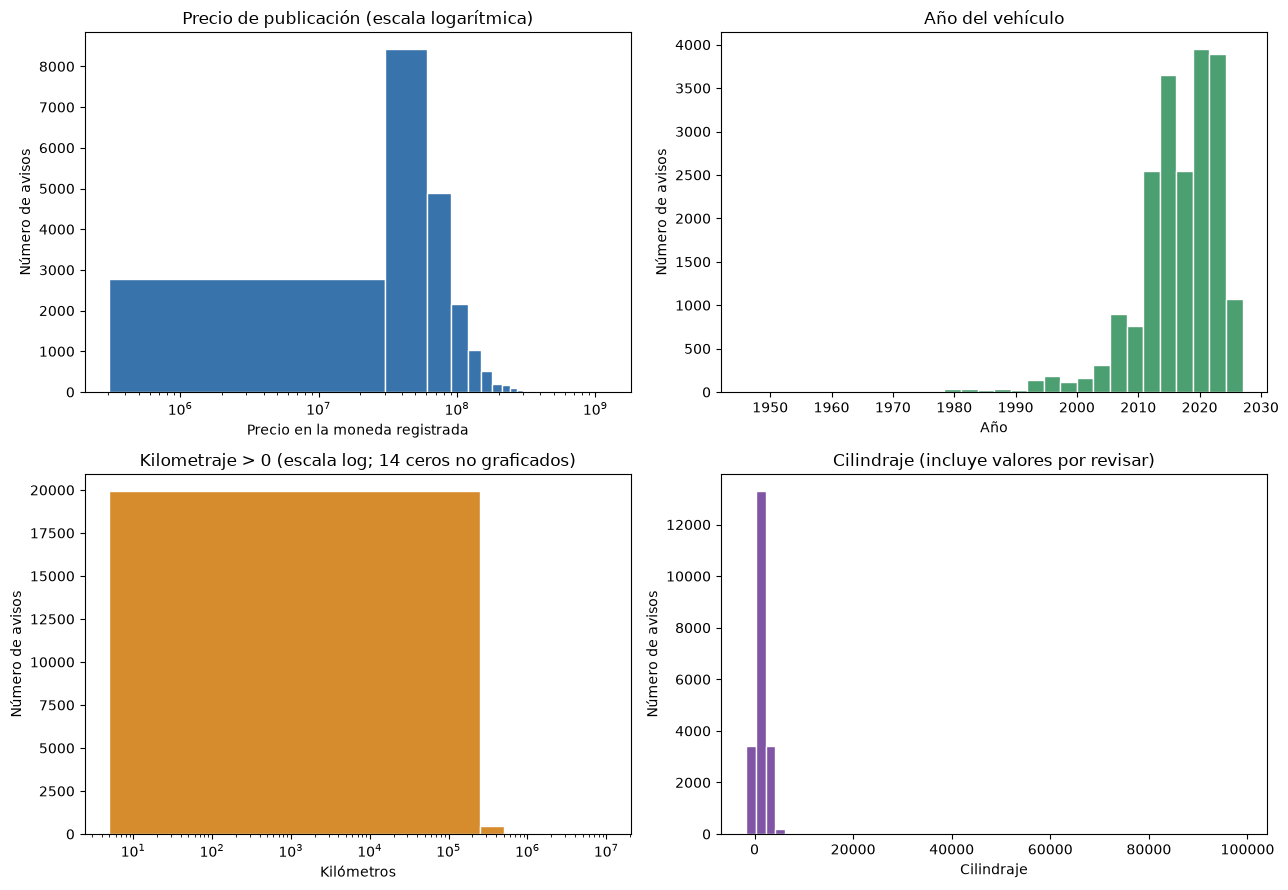

,precio,anio,kilometraje,cilindraje,num_fotos
precio,1.00,0.69,-0.56,0.13,0.11
anio,0.69,1.00,-0.74,-0.20,0.06
kilometraje,-0.56,-0.74,1.00,0.15,-0.06
cilindraje,0.13,-0.20,0.15,1.00,0.11
num_fotos,0.11,0.06,-0.06,0.11,1.00


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

positive_price = df.loc[df["precio"].gt(0), "precio"]
axes[0, 0].hist(positive_price, bins=40, color="#3973ac", edgecolor="white")
axes[0, 0].set_xscale("log")
axes[0, 0].set_title("Precio de publicación (escala logarítmica)")
axes[0, 0].set_xlabel("Precio en la moneda registrada")
axes[0, 0].set_ylabel("Número de avisos")

axes[0, 1].hist(df["anio"].dropna(), bins=30, color="#4c9f70", edgecolor="white")
axes[0, 1].set_title("Año del vehículo")
axes[0, 1].set_xlabel("Año")
axes[0, 1].set_ylabel("Número de avisos")

positive_km = df.loc[df["kilometraje"].gt(0), "kilometraje"]
axes[1, 0].hist(positive_km, bins=40, color="#d68b2c", edgecolor="white")
axes[1, 0].set_xscale("log")
axes[1, 0].set_title(f"Kilometraje > 0 (escala log; {df['kilometraje'].eq(0).sum()} ceros no graficados)")
axes[1, 0].set_xlabel("Kilómetros")
axes[1, 0].set_ylabel("Número de avisos")

axes[1, 1].hist(df["cilindraje"].dropna(), bins=50, color="#8055a5", edgecolor="white")
axes[1, 1].set_title("Cilindraje (incluye valores por revisar)")
axes[1, 1].set_xlabel("Cilindraje")
axes[1, 1].set_ylabel("Número de avisos")

fig.tight_layout()
plt.show()

display(df[["precio", "anio", "kilometraje", "cilindraje", "num_fotos"]].corr(method="spearman").round(3))

## 4. Variables categóricas
Se inspecciona el balance de categorías frecuentes. La cardinalidad de `marca`, `modelo`, `ciudad` y `departamento` puede afectar la codificación y la generalización; los conteos bajos no implican por sí solos que una variable deba descartarse.

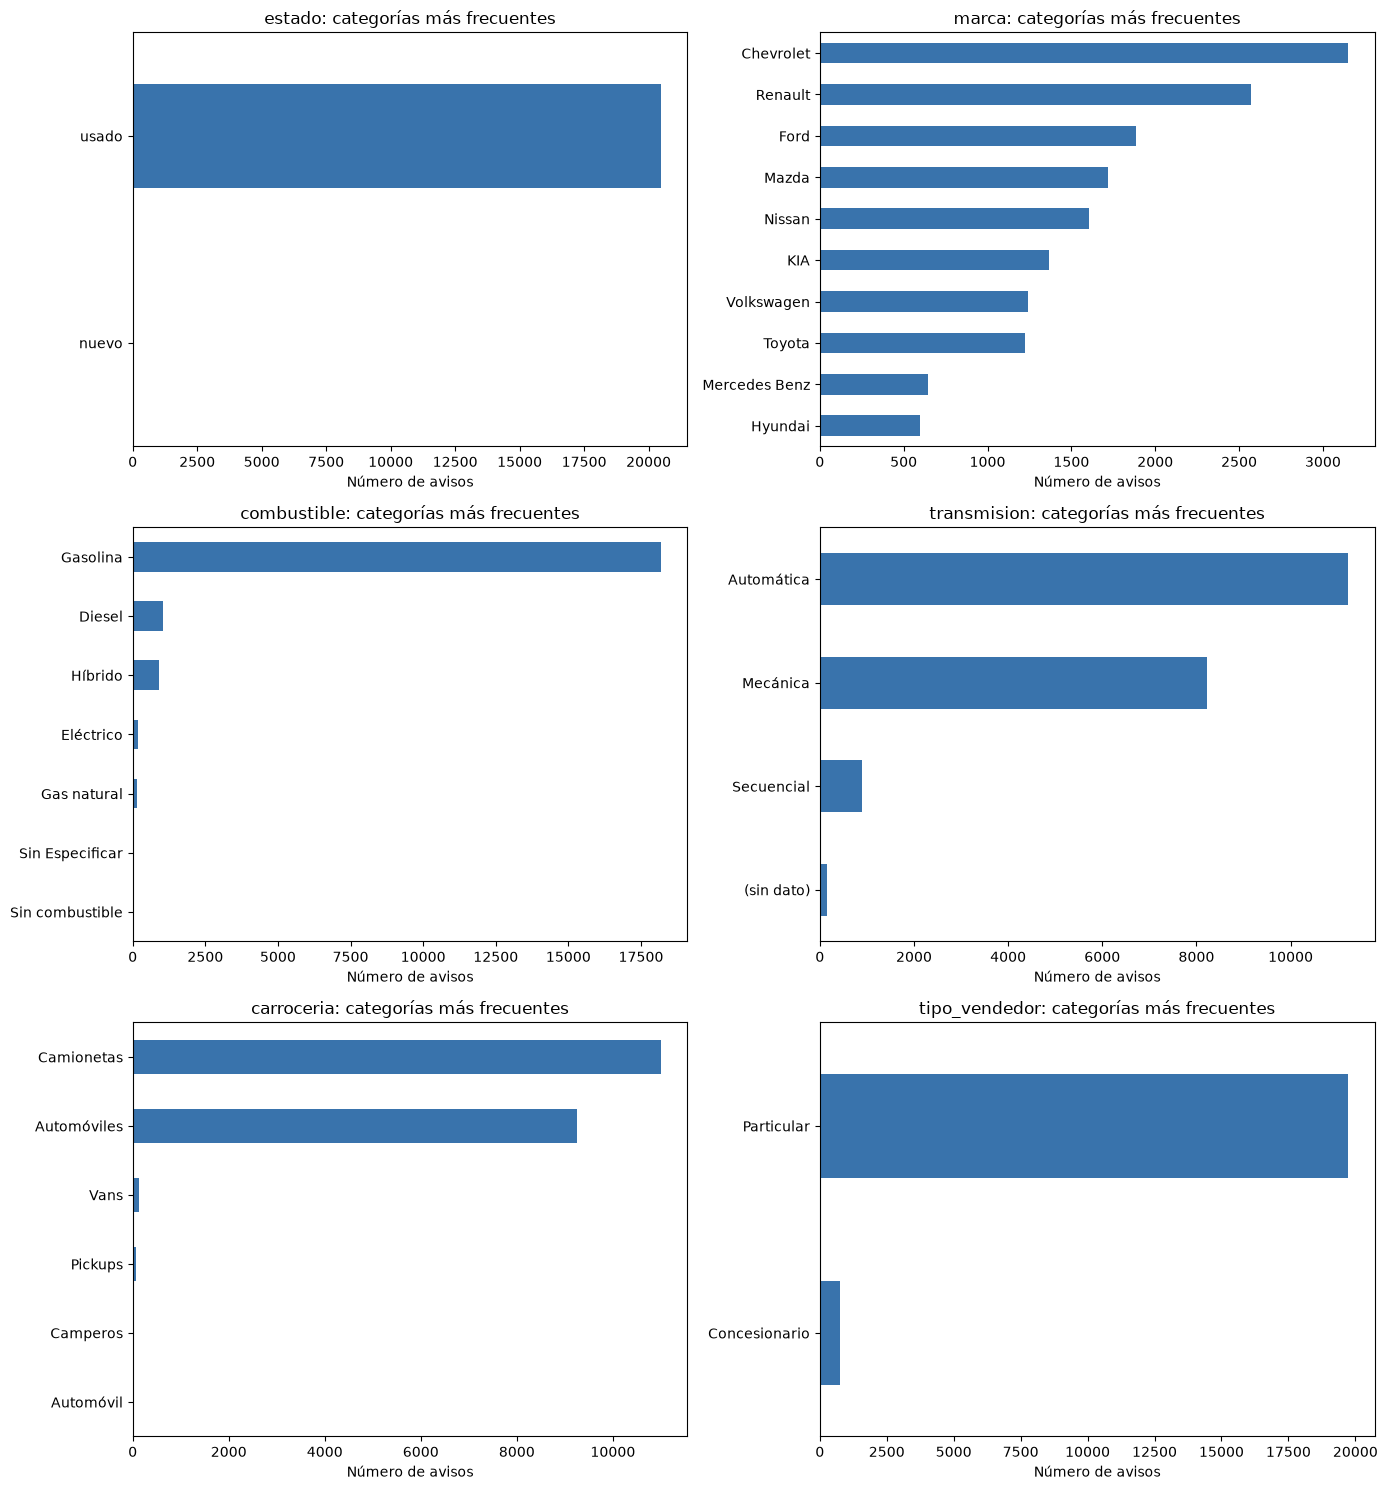

C:\Users\diego\AppData\Local\Temp\ipykernel_4324\3883687392.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  "categorias": df.select_dtypes(include="object").nunique(dropna=True),
C:\Users\diego\AppData\Local\Temp\ipykernel_4324\3883687392.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/

,categorias,%_nulos
id,20494,0.00
fecha_publicacion,20423,0.00
descripcion,15342,22.24
accesorios,9470,17.59
titulo,4205,0.00
version,3404,5.08
caracteristicas,1865,18.95
modelo,787,0.00
ciudad,295,0.00
ciudad_placa,226,0.07


In [5]:
categorical_cols = ["estado", "marca", "combustible", "transmision", "carroceria", "tipo_vendedor"]
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for ax, column in zip(axes.flat, categorical_cols):
    counts = df[column].fillna("(sin dato)").value_counts().head(10).sort_values()
    counts.plot(kind="barh", ax=ax, color="#3973ac")
    ax.set_title(f"{column}: categorías más frecuentes")
    ax.set_xlabel("Número de avisos")
    ax.set_ylabel("")

fig.tight_layout()
plt.show()

cardinality = pd.DataFrame({
    "categorias": df.select_dtypes(include="object").nunique(dropna=True),
    "%_nulos": (df.select_dtypes(include="object").isna().mean() * 100).round(2),
}).sort_values("categorias", ascending=False)
display(cardinality)

## 5. Relaciones iniciales con el precio
Se comparan medianas de precio por año y se observa precio frente a kilometraje. Estas asociaciones son descriptivas, no causales. La muestra del diagrama de dispersión solo afecta la visualización.

,avisos,mediana
anio,,
1992,23,"19,500,000.00"
1993,47,"23,000,000.00"
1994,63,"16,000,000.00"
1995,59,"24,000,000.00"
1996,56,"17,000,000.00"
1997,72,"18,250,000.00"
1998,81,"14,000,000.00"
1999,39,"20,500,000.00"
2000,42,"28,250,000.00"


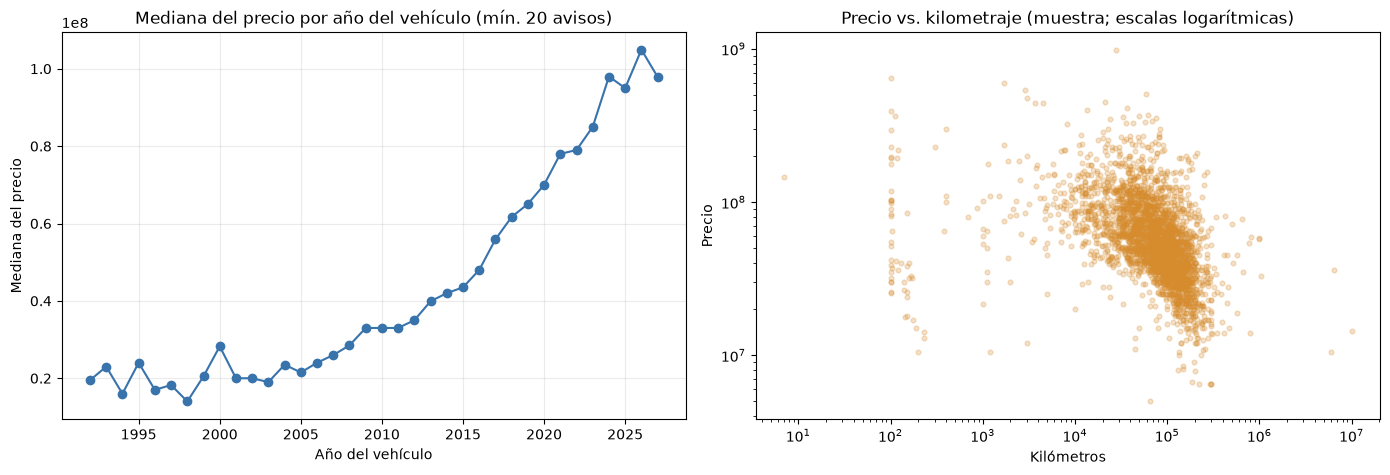

In [6]:
price_by_year = (
    df.groupby("anio", dropna=False)["precio"]
    .agg(avisos="count", mediana="median")
    .query("avisos >= 20")
    .sort_index()
)
display(price_by_year)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(price_by_year.index, price_by_year["mediana"], marker="o", color="#3973ac")
axes[0].set_title("Mediana del precio por año del vehículo (mín. 20 avisos)")
axes[0].set_xlabel("Año del vehículo")
axes[0].set_ylabel("Mediana del precio")
axes[0].grid(alpha=0.25)

scatter = df.loc[df["kilometraje"].gt(0), ["kilometraje", "precio"]].sample(
    n=min(3000, int(df["kilometraje"].gt(0).sum())), random_state=42
)
axes[1].scatter(scatter["kilometraje"], scatter["precio"], alpha=0.25, s=12, color="#d68b2c")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Precio vs. kilometraje (muestra; escalas logarítmicas)")
axes[1].set_xlabel("Kilómetros")
axes[1].set_ylabel("Precio")

fig.tight_layout()
plt.show()

## 6. Fechas y naturaleza de la muestra
`fecha_publicacion` describe cuándo se publicó cada aviso y `fecha_extraccion` cuándo se recolectó el archivo. Al ser una única extracción, las fechas de publicación no constituyen por sí solas una serie histórica de precios: cada vehículo aparece como un aviso en un corte del mercado.

Fechas de publicación válidas: 20,494 / 20,494
Rango de publicación: 2022-01-05 11:26:36+00:00 a 2026-11-04 17:49:44+00:00
Fechas de extracción válidas: 20,494 / 20,494
Rango de extracción: 2026-11-04 12:43:23+00:00 a 2026-11-04 12:43:23+00:00


C:\Users\diego\AppData\Local\Temp\ipykernel_4324\1310185590.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_ads = publication_date.dropna().dt.to_period("M").value_counts().sort_index()


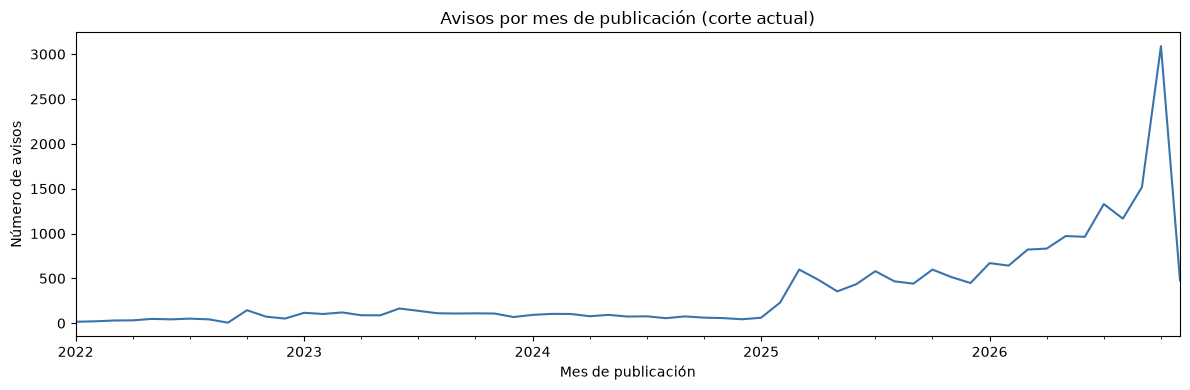

In [7]:
publication_date = pd.to_datetime(df["fecha_publicacion"], errors="coerce", utc=True)
extraction_date = pd.to_datetime(df["fecha_extraccion"], errors="coerce", utc=True)
print(f"Fechas de publicación válidas: {publication_date.notna().sum():,} / {len(df):,}")
print(f"Rango de publicación: {publication_date.min()} a {publication_date.max()}")
print(f"Fechas de extracción válidas: {extraction_date.notna().sum():,} / {len(df):,}")
print(f"Rango de extracción: {extraction_date.min()} a {extraction_date.max()}")

monthly_ads = publication_date.dropna().dt.to_period("M").value_counts().sort_index()
monthly_ads.plot(figsize=(12, 4), color="#3973ac", title="Avisos por mes de publicación (corte actual)")
plt.xlabel("Mes de publicación")
plt.ylabel("Número de avisos")
plt.tight_layout()
plt.show()

## 7. Hallazgos y variables para revisar en la siguiente fase

Completar esta lectura con las tablas y gráficos generados al ejecutar el notebook:

- **Posible objetivo:** `precio` para estimar el precio anunciado. El CSV registra una única moneda; confirmar semántica y unidad antes de modelar.
- **Candidatas iniciales:** `anio`, `kilometraje`, `marca`, `modelo`, `combustible`, `transmision`, `cilindraje`, `carroceria`, `ciudad`/`departamento`, `tipo_vendedor` y `num_fotos`. Revisar categorías raras, nulos y posibles redundancias antes de codificar.
- **Campos a excluir o evaluar con cuidado:** `id` (identificador, no predictor), `fuente` (constante), `fecha_extraccion` (constante en este corte) y `destacado` (posible atributo del anuncio/plataforma, verificar disponibilidad al momento de predecir). `titulo`, `descripcion`, `caracteristicas` y `accesorios` son texto libre y requieren una decisión explícita de privacidad y tratamiento.
- **Nulos:** `negociable`, `unico_dueno`, `torque`, `potencia` y `tipo_direccion` están muy incompletos; comparar su utilidad con la pérdida de filas o el uso de imputación antes de descartarlos.
- **Calidad numérica:** revisar los cilindrajes no positivos o muy altos, kilometrajes extremos y ceros, así como avisos con año posterior a la extracción. No son necesariamente errores: validar contra los avisos originales y definir reglas de negocio documentadas.
- **Validación/modelado posterior:** al ser datos transversales de anuncios en una fecha, una serie de tiempo de precio no está justificada con este archivo solamente. Antes de entrenar los tres modelos, definir objetivos comparables, dividir los datos sin filtrar información entre particiones y guardar cada pipeline de preprocesamiento junto con el modelo.

La selección final de variables debe apoyarse en conocimiento del dominio y evaluación en datos de validación, no solo en correlaciones o porcentajes de nulos.

## 8. Tratamiento conservador para conservar registros

Las plantillas sirven como lista de técnicas (faltantes, duplicados, categorías, atípicos, escalado y codificación), pero no conviene copiar sus eliminaciones de filas sin validar el contexto. En este dataset se propone:

1. **No usar `dropna()` sobre todo el DataFrame.** Para predictores incompletos, conservar el aviso; más adelante probar imputación (mediana para numéricas y categoría explícita como `No informado` para categóricas), acompañada de indicadores de faltante cuando aporte información. Los campos con más de 90% de nulos pueden excluirse del primer modelo, sin eliminar los avisos.
2. **Duplicados:** solo deduplicar si el identificador de aviso se repite, documentando cuál registro conservar. Los datos ya se generan deduplicando por `id`; confirmar de nuevo el conteo aquí.
3. **Atípicos:** no filtrar filas usando límites genéricos de boxplot/IQR. Revisar el dato con el aviso original; si un valor es imposible o está mal formado, marcarlo como faltante o corregirlo solo con evidencia, conservando el registro y agregando una bandera si es útil. Los extremos de precio pueden ser vehículos genuinos.
4. **Ceros y valores especiales:** kilometraje 0 puede ser legítimo en vehículos nuevos; cilindraje 0 también aparece en vehículos eléctricos, por lo que no se reemplaza automáticamente. Valores negativos de cilindraje sí requieren revisión, no borrado de la fila.
5. **Categorías y formatos:** normalizar espacios/capitalización en una copia de trabajo y fusionar categorías semánticamente equivalentes mediante un mapeo revisado. No aplicar reemplazos globales ni borrar tildes sin revisar las colisiones.
6. **Codificación/escalado:** no transformar todavía. En modelado, ajustar imputadores, codificadores y escaladores únicamente con entrenamiento (dentro de un `Pipeline`/`ColumnTransformer`) para evitar fuga de información y guardar el pipeline junto al modelo.

La celda siguiente estima cuántas filas se justificaría excluir por duplicado de `id` o precio objetivo faltante. Es un diagnóstico, no modifica `df` ni guarda un CSV tratado.

In [8]:
duplicate_id = df.duplicated(subset=["id"], keep="first")
missing_target = df["precio"].isna()
keep_for_supervised = ~duplicate_id & ~missing_target

retention = pd.DataFrame({
    "registros": [
        len(df),
        int(duplicate_id.sum()),
        int(missing_target.sum()),
        int((~keep_for_supervised).sum()),
        int(keep_for_supervised.sum()),
    ]
}, index=[
    "filas originales",
    "IDs repetidos (ocurrencias posteriores)",
    "precio objetivo faltante",
    "filas únicas que no cumplirían esos dos criterios",
    "filas retenidas para una tarea supervisada con precio",
])
display(retention)

categorical_review = []
for column in ["marca", "departamento", "ciudad", "combustible", "transmision", "carroceria"]:
    values = df[column].dropna().astype("string")
    normalized = values.str.normalize("NFKC").str.strip().str.casefold()
    categorical_review.append({
        "columna": column,
        "categorias_originales": values.nunique(),
        "categorias_tras_espacios_y_mayusculas": normalized.nunique(),
    })
display(pd.DataFrame(categorical_review).set_index("columna"))

,registros
filas originales,20494
IDs repetidos (ocurrencias posteriores),0
precio objetivo faltante,0
filas únicas que no cumplirían esos dos criterios,0
filas retenidas para una tarea supervisada con precio,20494


,categorias_originales,categorias_tras_espacios_y_mayusculas
columna,,
marca,89,87
departamento,58,43
ciudad,295,295
combustible,7,7
transmision,3,3
carroceria,6,6


## 9. Aplicación del tratamiento conservador

Se trabaja sobre `df_tratado`, una copia independiente. Se quitan únicamente IDs repetidos (si aparecieran), se homogeneizan categorías sin eliminar tildes y se completan categorías con pocos faltantes usando `NO INFORMADO`. No se imputan numéricas con estadísticas globales: esa imputación se ajustará dentro del pipeline de entrenamiento.

Para `cilindraje`, se conserva `cilindraje_original` y se corrigen a faltante valores negativos y casos mayores a 8.000 que coinciden exactamente con el kilometraje. En la inspección de la fuente cruda se encontraron 35 casos de esta coincidencia, además de 15 valores negativos. Otros extremos no se corrigen automáticamente: se conservan y se marcan. Se mantienen los años 2027 y los kilometrajes extremos para validarlos antes de modelar.

In [9]:
rows_before = len(df)
duplicate_ids_before = int(df.duplicated(subset=["id"], keep="first").sum())
df_tratado = df.drop_duplicates(subset=["id"], keep="last").copy()

category_cols = [
    "estado", "marca", "modelo", "version", "moneda", "combustible", "transmision",
    "color", "ciudad", "departamento", "carroceria", "tipo_vendedor", "pico_placa",
    "ciudad_placa", "negociable", "unico_dueno", "blindado", "tipo_direccion",
]
category_changes = []
for column in category_cols:
    before = df_tratado[column].nunique(dropna=True)
    values = (
        df_tratado[column].astype("string")
        .str.normalize("NFKC")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
    )
    df_tratado[column] = values.mask(values.eq(""), pd.NA)
    category_changes.append({
        "columna": column,
        "categorias_antes": before,
        "categorias_despues": df_tratado[column].nunique(dropna=True),
    })

low_missing_categoricals = ["version", "transmision", "pico_placa", "ciudad_placa"]
for column in low_missing_categoricals:
    df_tratado[column] = df_tratado[column].fillna("NO INFORMADO")

df_tratado["cilindraje_original"] = df_tratado["cilindraje"]
negative_cylinder = df_tratado["cilindraje"].lt(0)
cylinder_matches_odometer = (
    df_tratado["cilindraje"].gt(8_000)
    & df_tratado["cilindraje"].eq(df_tratado["kilometraje"])
)
df_tratado["flag_cilindraje_revisado"] = negative_cylinder | cylinder_matches_odometer
df_tratado.loc[df_tratado["flag_cilindraje_revisado"], "cilindraje"] = np.nan
df_tratado["flag_cilindraje_extremo"] = df_tratado["cilindraje_original"].gt(8_000)
df_tratado["flag_kilometraje_sentinel"] = df_tratado["kilometraje"].eq(9_999_999)
df_tratado["flag_kilometraje_extremo"] = df_tratado["kilometraje"].gt(1_000_000)

extraction_year = pd.to_datetime(
    df_tratado["fecha_extraccion"], errors="coerce", utc=True
).dt.year
df_tratado["flag_anio_posterior_extraccion"] = df_tratado["anio"].gt(extraction_year)

display(pd.DataFrame(category_changes).set_index("columna"))
treatment_summary = pd.Series({
    "filas originales": rows_before,
    "IDs repetidos detectados": duplicate_ids_before,
    "filas después del tratamiento": len(df_tratado),
    "cilindrajes corregidos a faltante (original conservado)": int(df_tratado["flag_cilindraje_revisado"].sum()),
    "cilindrajes extremos marcados": int(df_tratado["flag_cilindraje_extremo"].sum()),
    "kilometrajes centinela 9.999.999 marcados, sin modificar": int(df_tratado["flag_kilometraje_sentinel"].sum()),
    "kilometrajes mayores a 1.000.000 marcados, sin modificar": int(df_tratado["flag_kilometraje_extremo"].sum()),
    "años posteriores a la extracción, marcados sin modificar": int(df_tratado["flag_anio_posterior_extraccion"].sum()),
})
display(treatment_summary.to_frame("registros"))
assert len(df_tratado) == rows_before - duplicate_ids_before

,categorias_antes,categorias_despues
columna,,
estado,2,2
marca,89,87
modelo,787,784
version,3404,3375
moneda,1,1
combustible,7,7
transmision,3,3
color,17,17
ciudad,295,295


,registros
filas originales,20494
IDs repetidos detectados,0
filas después del tratamiento,20494
cilindrajes corregidos a faltante (original conservado),50
cilindrajes extremos marcados,169
"kilometrajes centinela 9.999.999 marcados, sin modificar",2
"kilometrajes mayores a 1.000.000 marcados, sin modificar",25
"años posteriores a la extracción, marcados sin modificar",53


## 10. Vista inicial para modelado y columnas diferidas

La eliminación de columnas se aplica solo a una **vista de trabajo**, no al archivo tratado completo. Se excluyen identificadores, campos constantes, texto libre (para una fase NLP posterior), campos con más de 90% de faltantes y `destacado`, que describe promoción del aviso y podría no estar disponible en el momento de predecir. Esta selección es preliminar y se debe comparar con alternativas en validación.

In [10]:
excluded_from_first_view = {
    "id": "identificador del aviso; no es una característica del vehículo",
    "fuente": "un único valor en este archivo",
    "fecha_extraccion": "un único corte de extracción",
    "moneda": "una sola moneda en el archivo",
    "destacado": "promoción del aviso; disponibilidad futura por confirmar",
    "torque": "94.95% de faltantes; evaluar en una etapa posterior",
    "potencia": "94.95% de faltantes; evaluar en una etapa posterior",
    "tipo_direccion": "94.95% de faltantes; evaluar en una etapa posterior",
    "unico_dueno": "94.95% de faltantes; evaluar en una etapa posterior",
    "negociable": "94.95% de faltantes; evaluar en una etapa posterior",
    "titulo": "texto libre; revisar NLP y redundancia",
    "descripcion": "texto libre; revisar privacidad y NLP",
    "caracteristicas": "texto libre; revisar NLP",
    "accesorios": "texto libre; revisar NLP",
    "cilindraje_original": "copia de auditoría; no usar como predictor",
    "flag_cilindraje_revisado": "indicador de calidad; no usar en baseline",
    "flag_cilindraje_extremo": "indicador de calidad; no usar en baseline",
    "flag_kilometraje_sentinel": "indicador de calidad; no usar en baseline",
    "flag_kilometraje_extremo": "indicador de calidad; no usar en baseline",
    "flag_anio_posterior_extraccion": "indicador de calidad; no usar en baseline",
}
model_columns = [column for column in df_tratado.columns if column not in excluded_from_first_view]
df_modelo_candidata = df_tratado[model_columns].copy()
display(pd.DataFrame({"motivo": pd.Series(excluded_from_first_view)}))
print(f"Vista candidata: {df_modelo_candidata.shape[0]:,} filas x {df_modelo_candidata.shape[1]} columnas")
print("Columnas candidatas:", model_columns)

,motivo
id,identificador del aviso; no es una característ...
fuente,un único valor en este archivo
fecha_extraccion,un único corte de extracción
moneda,una sola moneda en el archivo
destacado,promoción del aviso; disponibilidad futura por...
torque,94.95% de faltantes; evaluar en una etapa post...
potencia,94.95% de faltantes; evaluar en una etapa post...
tipo_direccion,94.95% de faltantes; evaluar en una etapa post...
unico_dueno,94.95% de faltantes; evaluar en una etapa post...
negociable,94.95% de faltantes; evaluar en una etapa post...


Vista candidata: 20,494 filas x 20 columnas
Columnas candidatas: ['estado', 'marca', 'modelo', 'version', 'anio', 'kilometraje', 'precio', 'combustible', 'transmision', 'cilindraje', 'color', 'ciudad', 'departamento', 'carroceria', 'tipo_vendedor', 'pico_placa', 'ciudad_placa', 'num_fotos', 'fecha_publicacion', 'blindado']


## 11. Guardado y controles finales

Se guarda un CSV tratado aparte, con todas las filas y columnas originales más las variables de auditoría. El CSV fuente se conserva sin cambios. No se escalan ni codifican variables en esta etapa: esos transformadores se deben ajustar solo con los datos de entrenamiento y persistirse junto al modelo.

In [11]:
treated_path = project_root / "Scripts" / "data" / "carroya_dataset_tratado.csv"
df_tratado.to_csv(treated_path, index=False, encoding="utf-8-sig")

assert len(df_tratado) == len(df) - duplicate_ids_before
assert df_tratado["precio"].isna().sum() == df["precio"].isna().sum()
assert df_tratado["id"].is_unique
print(f"Archivo tratado guardado: {treated_path}")
print(f"Filas conservadas: {len(df_tratado):,} de {len(df):,}")
print(f"Precio faltante: {df_tratado['precio'].isna().sum():,}")
print(f"Cilindraje original conservado para auditoría: {'cilindraje_original' in df_tratado.columns}")

Archivo tratado guardado: c:\Users\diego\Documents\UNAL-26-2\Ciencia de Los Datos\Proyecto\Scripts\data\carroya_dataset_tratado.csv
Filas conservadas: 20,494 de 20,494
Precio faltante: 0
Cilindraje original conservado para auditoría: True
